# Theorie vs. Messung: Galaxy-Galaxy Lensing (Bayes)

- Messung: `ggl_measurements.npz` (aus `G2LShearProfile.ipynb`), Kovarianz: OneCovariance (voll, alle Bins).
- Modell: NN-Emulator, Kosmologie (5) global + HOD (5) je Lens-Bin, siehe `g2l_nn.py` / `G2LTheory.ipynb`.
- Chain: `python run_mcmc.py --out chain_trial4_v2.npz` (in `/home/rhoffmann/MA/Modelling`).
- Variante B: NN mit z-Eingang. Ergebnisse sind vorlaeufig, bis Emulator und MCMC-Konvergenz ausreichend validiert sind.
- Hinweis: Ketten, die vor der Umstellung auf direkte NN-Auswertung am Lens-z-Gitter berechnet wurden, verwenden ein anderes Vorhersagemodell; fuer konsistente Posterior-Plots eine neue Kette berechnen.

In [1]:
import sys
sys.path.insert(0, '/home/rhoffmann/MA/Modelling')
import numpy as np
import matplotlib.pyplot as plt
import corner
import g2l_nn as g

CHAIN = '/home/rhoffmann/MA/Modelling/chain_trial4_v2.npz'
BURN, THIN = 0.5, 10          # Burn-in-Anteil, Ausduennen

data, theory, space, post = g.build()
ch = np.load(CHAIN, allow_pickle=True)
chain, lnp = ch['chain'], ch['lnprob']
nstep, nw, nd = chain.shape
b = int(BURN*nstep)
flat = chain[b::THIN].reshape(-1, nd)
flat_lnp = lnp[b::THIN].reshape(-1)
print(f'{nstep} Schritte, {nw} Walker, {flat.shape[0]} Samples nach Burn-in/Thinning')
try:
    import emcee
    print('Autokorrelationszeit (max):', np.nanmax(emcee.autocorr.integrated_time(chain[b:], quiet=True)).round(1))
except Exception as e:
    print('tau:', e)

5000 Schritte, 96 Walker, 24000 Samples nach Burn-in/Thinning


The chain is shorter than 50 times the integrated autocorrelation time for 30 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 50;
tau: [236.94782766 232.41413046 234.71374168 219.31613505 216.39221817
 232.61903111 237.34159683 226.96051269 218.1895688  229.2768721
 220.37918221 226.74294829 226.6508795  215.01717686 230.28214794
 225.71354839 229.19307071 225.47193211 224.61955647 226.66857945
 252.89978745 244.69391252 246.72004694 259.83728852 220.78860721
 236.23368359 214.70428537 220.91082323 219.07719853 240.56150068]


Autokorrelationszeit (max): 259.8


In [2]:
source_bin_labels = {
    1: r'TOMOBIN 1 ($0.11 < z_B < 0.42$)',
    2: r'TOMOBIN 2 ($0.43 < z_B < 0.58$)',
    3: r'TOMOBIN 3 ($0.59 < z_B < 0.71$)',
    4: r'TOMOBIN 4 ($0.72 < z_B < 0.90$)',
    5: r'TOMOBIN 5 ($0.91 < z_B < 1.14$)',
    6: r'TOMOBIN 6 ($1.15 < z_B < 2.00$)',
}

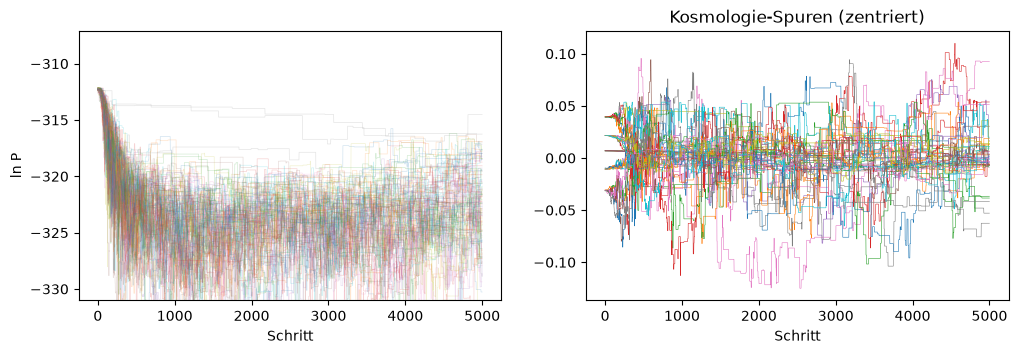

In [3]:
# Konvergenz: ln P und Walker-Spuren
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(lnp, alpha=0.2, lw=0.5); axes[0].set_ylim(np.percentile(lnp, 1), lnp.max()+5)
axes[0].set_xlabel('Schritt'); axes[0].set_ylabel('ln P')
for j in range(5):
    axes[1].plot(chain[:, :8, j] - chain[:, :8, j].mean(), lw=0.4)
axes[1].set_title('Kosmologie-Spuren (zentriert)'); axes[1].set_xlabel('Schritt')
plt.show()

In [4]:
# Parameter-Tabelle: Median, 16./84. Perzentil
best = flat[np.argmax(flat_lnp)]
print(f'{"Parameter":28s} {"Median":>9s} {"-1sig":>8s} {"+1sig":>8s} {"Best":>9s}')
for j, n in enumerate(space.names):
    q16, q50, q84 = np.percentile(flat[:, j], [16, 50, 84])
    print(f'{n:28s} {q50:9.3f} {q50-q16:8.3f} {q84-q50:8.3f} {best[j]:9.3f}')
chi2_best = data.chi2(theory.model_vector(best, space))
print(f'\nchi2_best = {chi2_best:.1f} bei N = {data.n}, Parameter = {nd}, chi2/dof = {chi2_best/(data.n-nd):.2f}')

Parameter                       Median    -1sig    +1sig      Best
Om_c                             0.426    0.032    0.033     0.394
Om_b                             0.051    0.007    0.006     0.060
h                                0.766    0.043    0.035     0.807
sigma_8                          0.609    0.007    0.011     0.601
n_s                              1.083    0.020    0.013     1.098
BGS_0.1-0.2:alpha                0.600    0.336    0.270     0.983
BGS_0.1-0.2:sigma                0.420    0.263    0.309     0.994
BGS_0.1-0.2:log10_Mth           11.589    0.069    0.100    11.823
BGS_0.1-0.2:log10_Mprime        15.228    0.930    1.099    13.939
BGS_0.1-0.2:beta                 1.489    0.518    0.395     1.980
BGS_0.2-0.3:alpha                0.527    0.332    0.328     0.951
BGS_0.2-0.3:sigma                0.441    0.274    0.304     0.438
BGS_0.2-0.3:log10_Mth           12.010    0.063    0.115    11.997
BGS_0.2-0.3:log10_Mprime        15.547    0.931    0.864    14

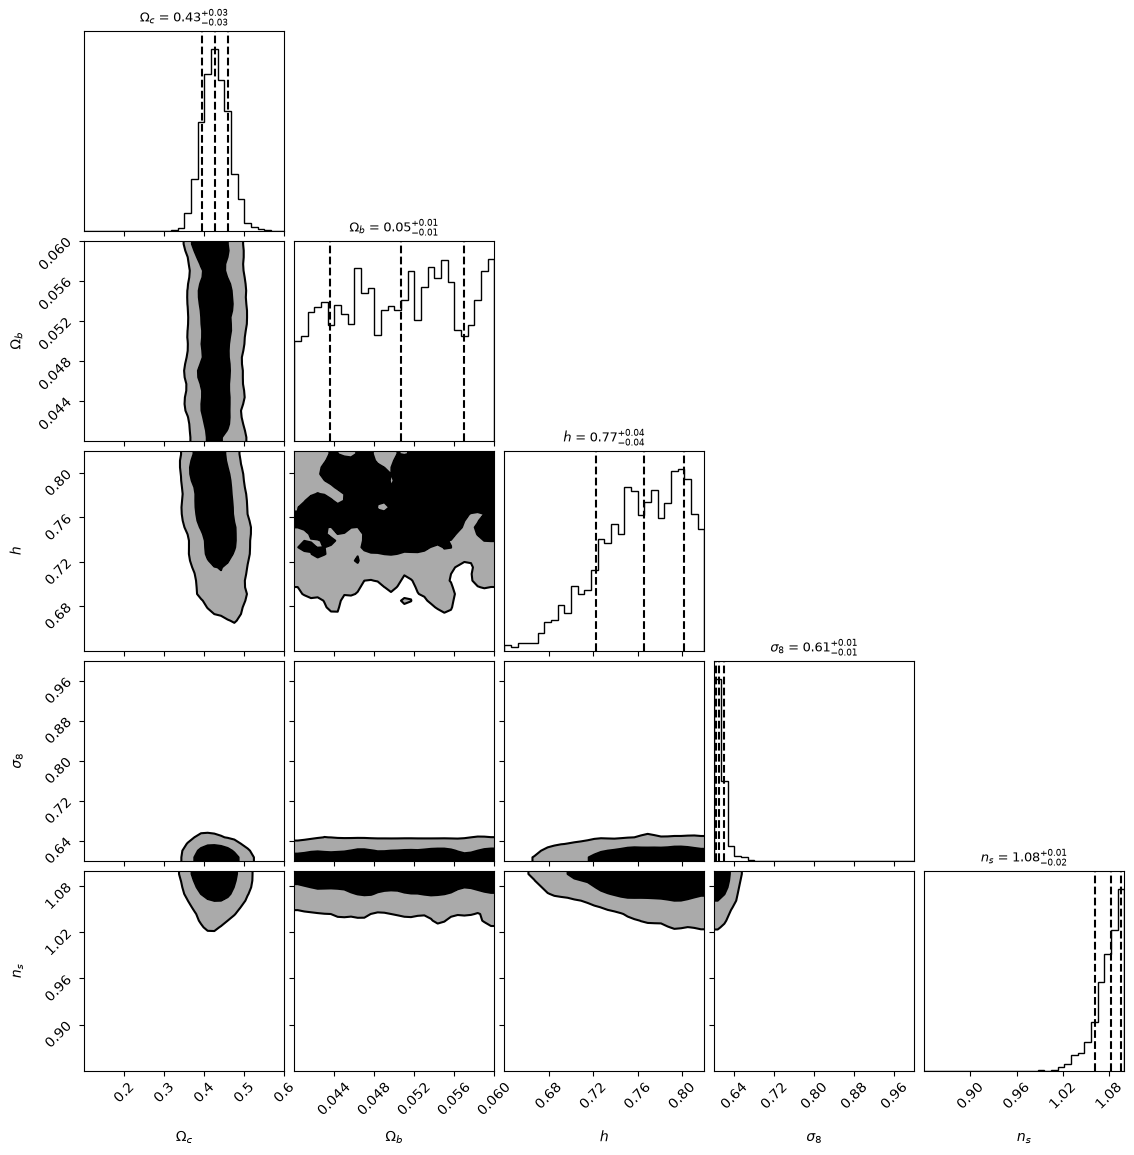

In [5]:
# Corner: Kosmologie (68 %, 95 % Konturen, 16/50/84-Perzentile)
kw = dict(quantiles=[0.16, 0.5, 0.84], levels=(0.68, 0.95), show_titles=True, title_kwargs=dict(fontsize=9),
          plot_datapoints=False, fill_contours=True, smooth=1.0, bins=30)
corner.corner(flat[:, :5], labels=space.labels[:5], range=list(zip(space.lo[:5], space.hi[:5])), **kw)
plt.show()

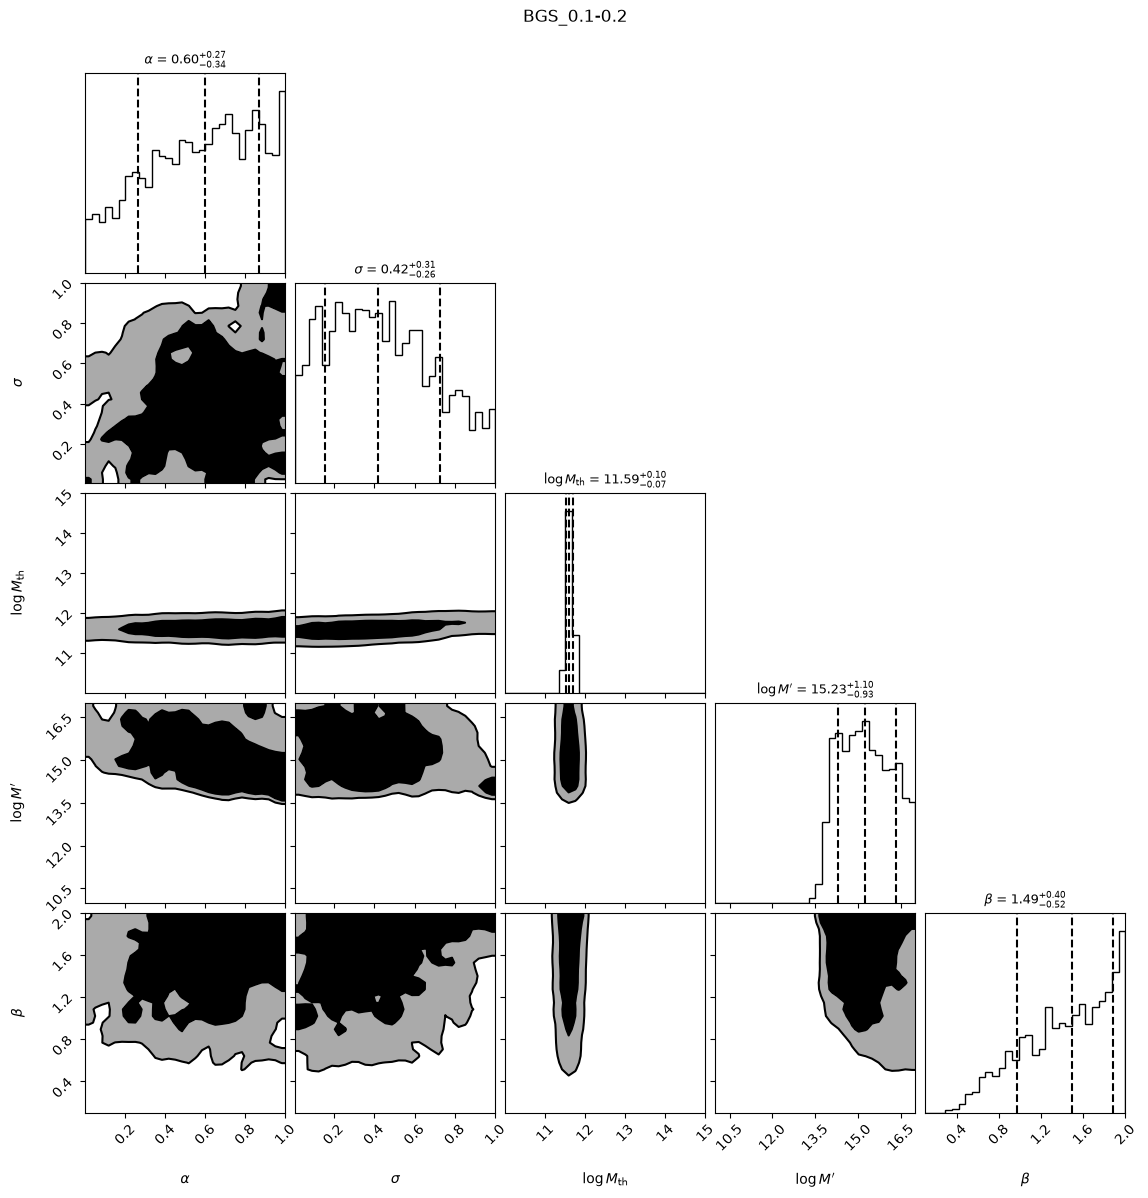

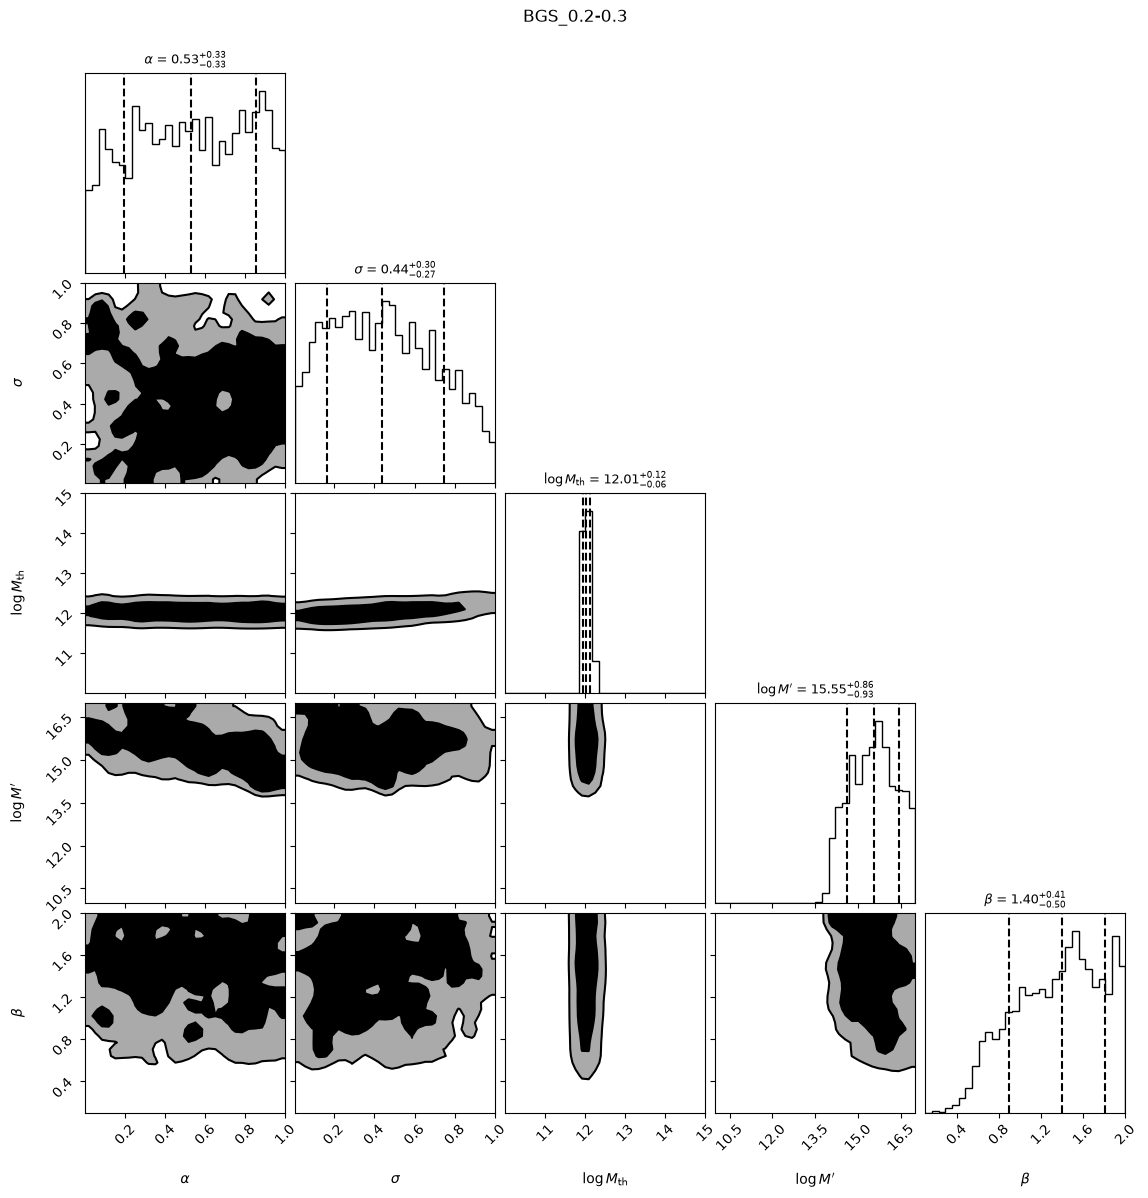

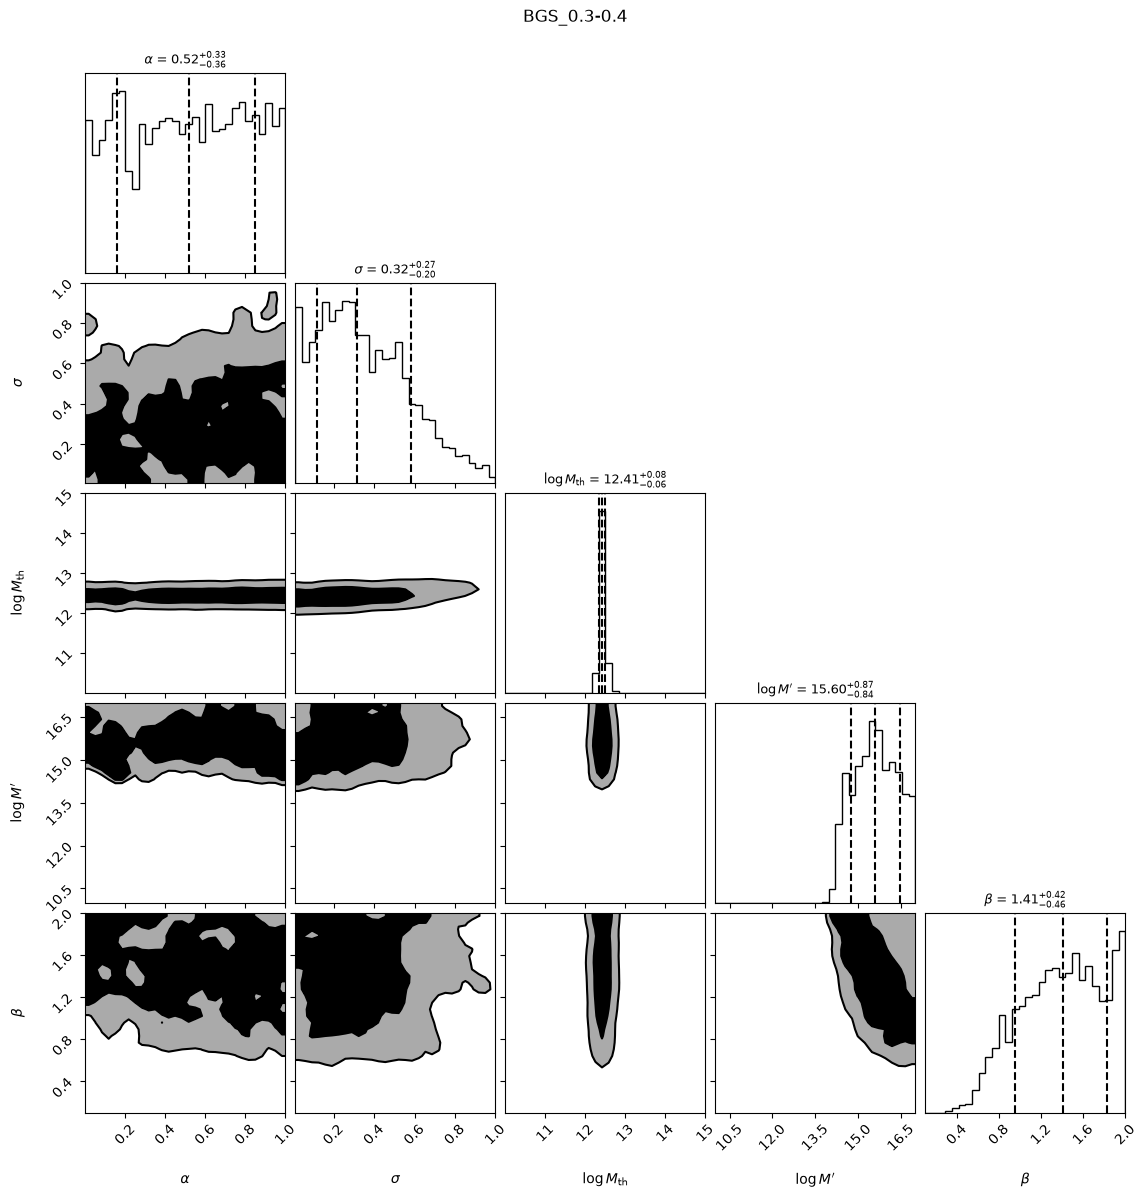

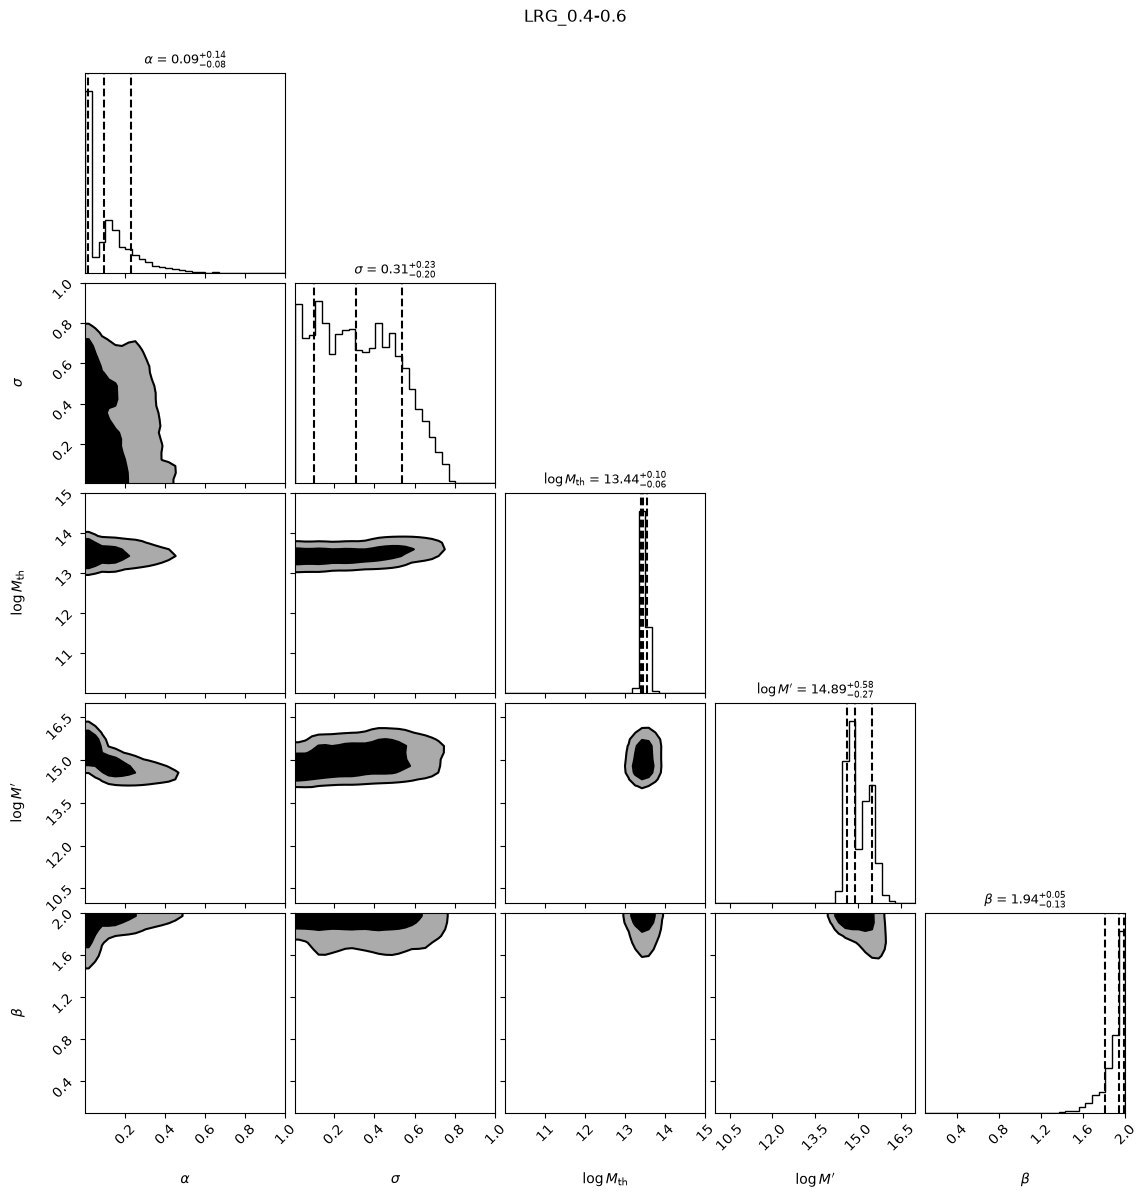

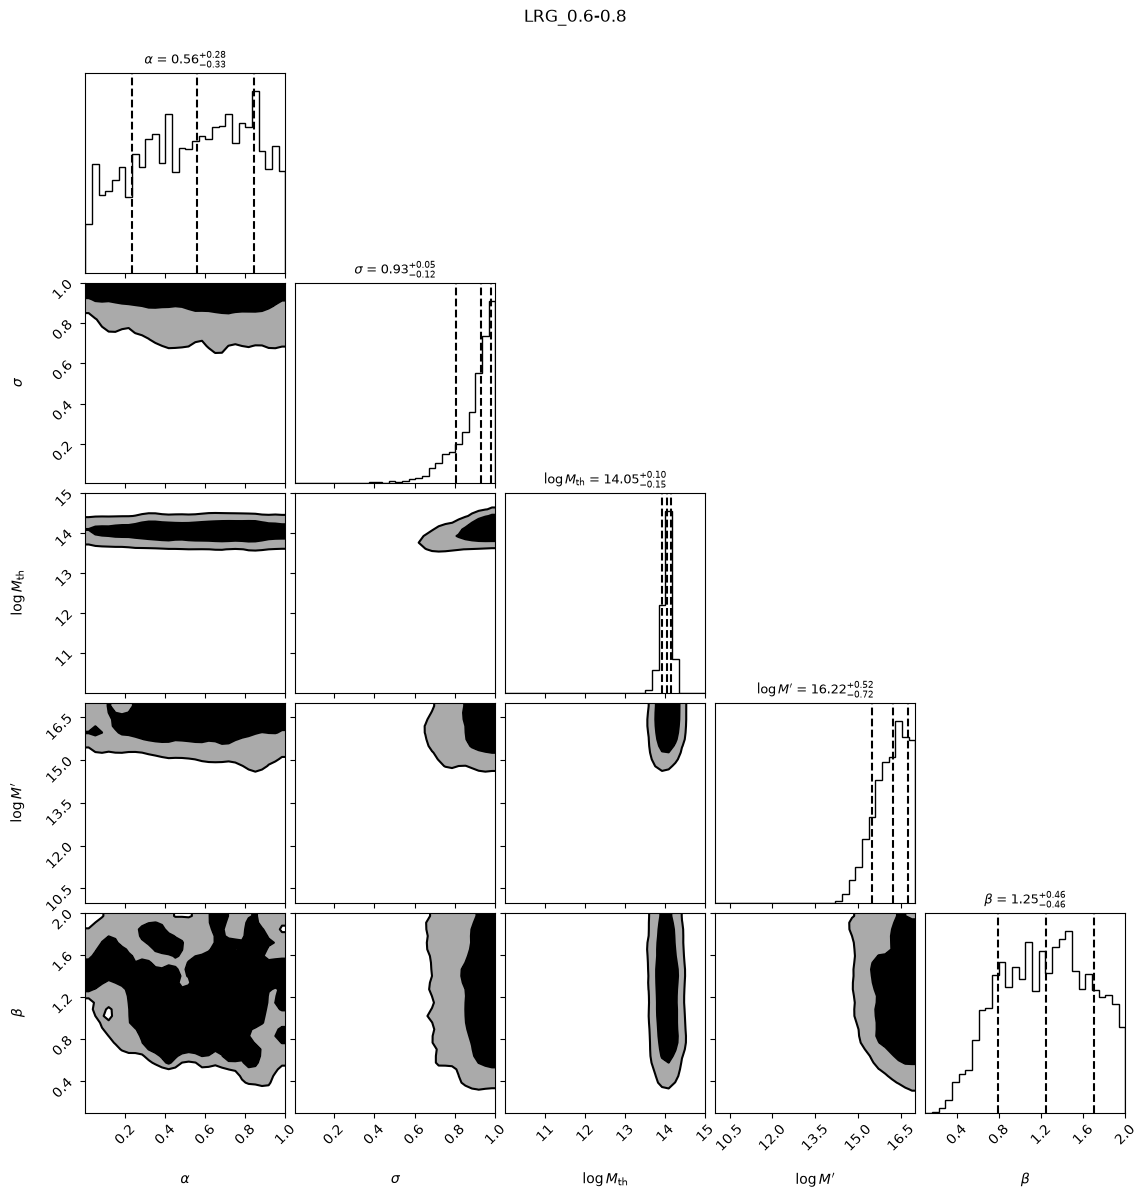

In [6]:
# Corner: HOD je Lens-Bin
for i, lens in enumerate(space.lens_names):
    sl = slice(5+5*i, 10+5*i)
    corner.corner(flat[:, sl], labels=[l.split('\n')[0] for l in space.labels[sl]],
                  range=list(zip(space.lo[sl], space.hi[sl])), **kw)
    plt.suptitle(lens, y=1.02); plt.show()

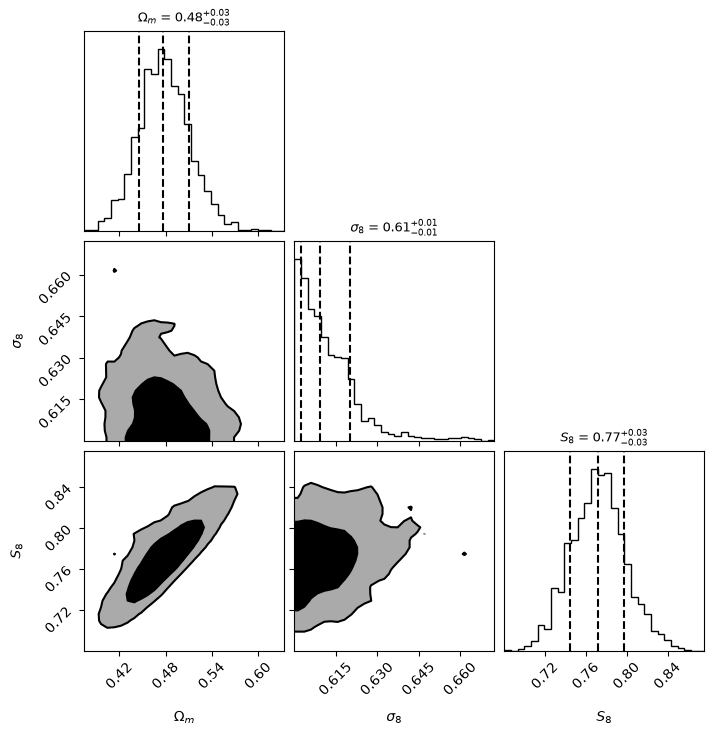

In [7]:
# Kosmologie + abgeleitet: S8 = sigma8 sqrt(Om/0.3)
Om = (flat[:, 0] + flat[:, 1])
S8 = flat[:, 3]*np.sqrt(Om/0.3)
corner.corner(np.column_stack([Om, flat[:, 3], S8]), labels=[r'$\Omega_m$', r'$\sigma_8$', r'$S_8$'], **kw)
plt.show()

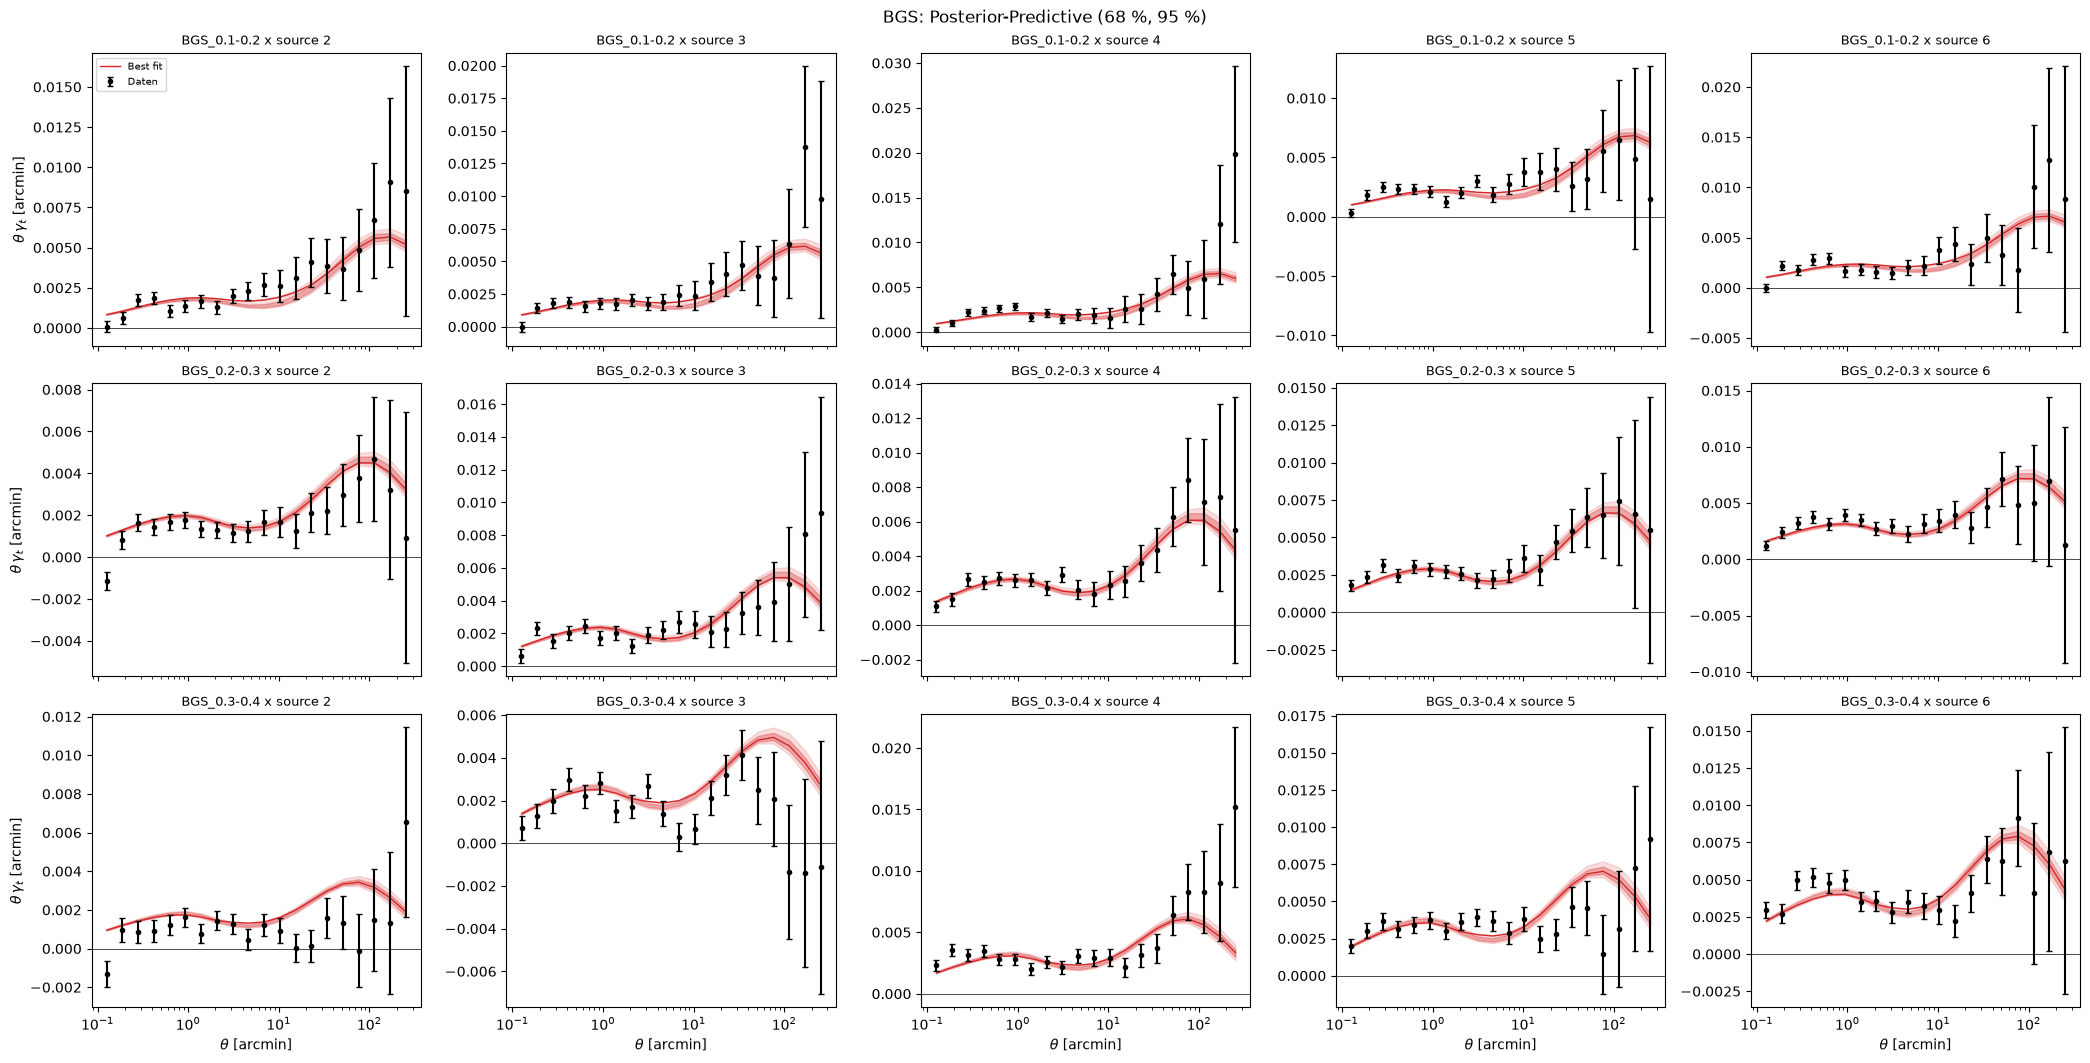

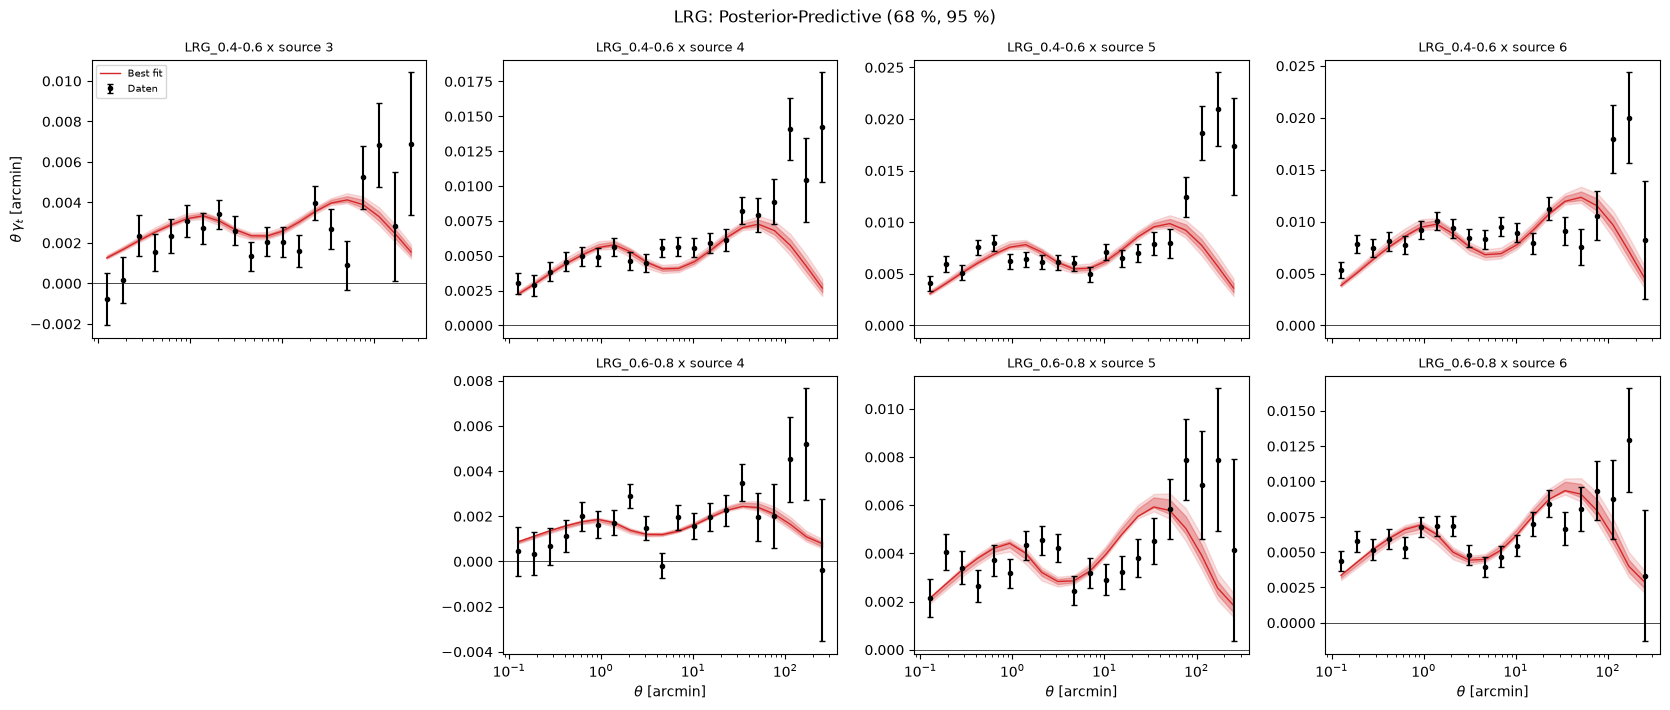

In [8]:
# Posterior-Predictive: gamma_t je Lens x Source (Median + 68/95 %-Band), Messung mit OneCov-Fehlern
rng = np.random.default_rng(0)
draws = flat[rng.choice(flat.shape[0], 300, replace=False)]
models = np.array([theory.model_vector(t, space) for t in draws])
lo95, lo68, med, hi68, hi95 = np.percentile(models, [2.5, 16, 50, 84, 97.5], axis=0)
mbest = theory.model_vector(best, space)

samples = {'BGS': [l for l in space.lens_names if l.startswith('BGS')],
           'LRG': [l for l in space.lens_names if l.startswith('LRG')]}
for sample, lens_names in samples.items():
    if not lens_names:
        continue
    src_bins = sorted({sb for ln, sb in data.combos if ln in lens_names})
    fig, axes = plt.subplots(len(lens_names), len(src_bins), figsize=(4.2*len(src_bins), 3.6*len(lens_names)),
                             squeeze=False, sharex=True)
    for a, ln in enumerate(lens_names):
        for bb, sb in enumerate(src_bins):
            ax = axes[a, bb]
            if (ln, sb) not in data.combos:
                ax.axis('off'); continue
            i = data.combos.index((ln, sb)); sl = data.slices[i]; th = data.theta[i]
            ax.fill_between(th, th*lo95[sl], th*hi95[sl], color='tab:red', alpha=0.15)
            ax.fill_between(th, th*lo68[sl], th*hi68[sl], color='tab:red', alpha=0.3)
            ax.plot(th, th*mbest[sl], color='tab:red', lw=1, label='Best fit')
            ax.errorbar(th, th*data.gt[i], yerr=th*data.sig_diag[i], fmt='o', ms=3, capsize=2, color='k', label='Daten')
            ax.axhline(0, color='k', lw=0.5); ax.set_xscale('log')
            ax.set_title(f'{ln} x source {sb}', fontsize=9)
            if bb == 0: ax.set_ylabel(r'$\theta\,\gamma_t$ [arcmin]')
            if a == len(lens_names)-1: ax.set_xlabel(r'$\theta$ [arcmin]')
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f'{sample}: Posterior-Predictive (68 %, 95 %)')
    fig.tight_layout(); plt.show()

In [9]:
# chi2 je Kombination (Best fit, Diagonale)
print('chi2_diag / N je Kombination (Best fit):')
for i, (ln, sb) in enumerate(data.combos):
    sl = data.slices[i]
    c = np.sum(((data.d[sl]-mbest[sl])/data.sig[sl])**2)
    print(f'  {ln:12s} S{sb}: {c:6.1f} / {sl.stop-sl.start}')

chi2_diag / N je Kombination (Best fit):
  BGS_0.1-0.2  S2:   20.1 / 20
  BGS_0.1-0.2  S3:   13.0 / 20
  BGS_0.1-0.2  S4:   22.7 / 20
  BGS_0.1-0.2  S5:   24.7 / 20
  BGS_0.1-0.2  S6:   26.1 / 20
  BGS_0.2-0.3  S2:   36.5 / 20
  BGS_0.2-0.3  S3:   19.2 / 20
  BGS_0.2-0.3  S4:    9.9 / 20
  BGS_0.2-0.3  S5:    9.2 / 20
  BGS_0.2-0.3  S6:   14.6 / 20
  BGS_0.3-0.4  S2:   45.4 / 20
  BGS_0.3-0.4  S3:   32.1 / 20
  BGS_0.3-0.4  S4:   33.8 / 20
  BGS_0.3-0.4  S5:   28.7 / 20
  BGS_0.3-0.4  S6:   26.3 / 20
  LRG_0.4-0.6  S3:   28.0 / 20
  LRG_0.4-0.6  S4:   47.7 / 20
  LRG_0.4-0.6  S5:   81.3 / 20
  LRG_0.4-0.6  S6:   60.8 / 20
  LRG_0.6-0.8  S4:   24.9 / 20
  LRG_0.6-0.8  S5:   45.6 / 20
  LRG_0.6-0.8  S6:   32.6 / 20
